# Kalman Filter Altitude and Vertical Velocity

Fuse the accelerometer and barometer with a linear Kalman filter. The accelerometer *predicts* how altitude (h) and vertical velocity (v) change between samples, and the barometer *corrects* the altitude. We use the noise levels measured in the naive notebook, tune the filter on one stair climb, and then test it on recordings it hasn't seen. Press `shift + enter` to run each cell.

In [2]:
import numpy as np

import utils

## Settings

Every recording must start and end with the board held still for at least `REF_TIME_S` seconds. The start window sets the references (zero points), and the end window is used to score the results.

In [29]:
# Recordings: name -> (folder, true height change in meters). Use None if the
# height change wasn't measured.
RECORDINGS = {
    "stairs_up":   ("recordings/stairs_up", 16 * 0.193),
    "stairs_down": ("recordings/stairs_down", -16 * 0.193),
    "round_trip":  ("recordings/stairs_round", 0.0),
    "lift":        ("recordings/lift", None),
}

# Recording used to tune the filter (the rest are used for evaluation)
TUNE_NAME = "stairs_up"

# Time to measure barometer and accelerometer reference points
REF_TIME_S = 2.0

# Noise std devs measured from the static recording (naive notebook)
SIGMA_A = 0.0212    # accelerometer (m/s²)
SIGMA_B = 0.0255    # barometer (m)

## Kalman Filter

The state is altitude and vertical velocity, $x = [h, v]^\mathsf{T}$. The accelerometer is the input $u$, and the barometer is the measurement $z$.

**Predict** (every accelerometer sample): the same constant-acceleration kinematics we used in the naive notebook, plus a step that grows the uncertainty.

$$
\hat{x}^- = F \hat{x} + B u, \qquad P^- = F P F^\mathsf{T} + Q
$$

$$
F = \begin{bmatrix} 1 & \Delta t \\ 0 & 1 \end{bmatrix}, \quad
B = \begin{bmatrix} \tfrac{1}{2}\Delta t^2 \\ \Delta t \end{bmatrix}, \quad
Q = B B^\mathsf{T} \sigma_a^2
$$

**Predict the measurement**: what the barometer *should* read if the prediction is right. $D$ is how the input directly affects the measurement. The barometer doesn't respond to acceleration, so $D = 0$ here, but we keep it so the equations match the general form.

$$
\hat{z} = H \hat{x}^- + D u
$$

**Correct** (every barometer sample): blend the prediction with the measurement, weighted by the Kalman gain $K$.

$$
y = z - \hat{z}, \qquad S = H P^- H^\mathsf{T} + R, \qquad K = P^- H^\mathsf{T} S^{-1}
$$

$$
\hat{x} = \hat{x}^- + K y, \qquad P = (I - K H) P^-
$$

$$
H = \begin{bmatrix} 1 & 0 \end{bmatrix}, \quad D = 0, \quad R = \sigma_b^2
$$

In [30]:
class KalmanFilter1D:
    """
    Event-driven linear Kalman filter for 1D vertical motion. The state has
    two elements, x = [h, v]: altitude and vertical velocity. The input is
    vertical acceleration (u), and the measurement is barometer altitude (z).
    """

    def __init__(self, sigma_a, sigma_b, sigma_v0=0.1):
        self.sigma_a = sigma_a

        # State estimate x = [h, v] and its covariance P (start at rest, h = 0)
        self.x = np.array([0.0, 0.0])
        self.P = np.diag([sigma_b**2, sigma_v0**2])

        # Constant matrices: the barometer measures h only (H), doesn't
        # respond directly to acceleration (D = 0), and has noise R
        self.H = np.array([[1.0, 0.0]])
        self.D = np.array([[0.0]])
        self.R = np.array([[sigma_b**2]])

        # Most recent acceleration, held constant until the next sample
        self.u = 0.0
        self.t_last = None

    def predict(self, t, a=None):
        """
        Propagate the state to time t using the held acceleration (the input
        from the previous step). If a new acceleration reading is given, hold
        it for the next step.
        """
        if self.t_last is not None:
            # System and process noise matrices depend on dt, so rebuild them
            dt = t - self.t_last
            F = np.array([[1.0, dt],
                          [0.0, 1.0]])
            B = np.array([0.5 * dt**2, dt])
            Q = np.outer(B, B) * self.sigma_a**2    # Q = B B^T sigma_a^2

            self.x = F @ self.x + B * self.u        # 1a) predict state
            self.P = F @ self.P @ F.T + Q           # 1b) predict covariance

        # Hold the new acceleration for the next step
        self.t_last = t
        if a is not None:
            self.u = a

        return self.x

    def correct(self, z):
        """Pull the estimate toward the barometer's altitude measurement"""
        u = np.array([self.u])
        z_hat = self.H @ self.x + self.D @ u        # 1c) predict measurement
        y = z - z_hat                               # innovation
        S = self.H @ self.P @ self.H.T + self.R     # innovation covariance
        K = self.P @ self.H.T @ np.linalg.inv(S)    # 2a) Kalman gain

        self.x = self.x + K @ y                     # 2b) update state
        self.P = (np.eye(2) - K @ self.H) @ self.P  # 2c) update covariance

        return self.x

## Helper Functions

In [31]:
def load_and_reference(path, ref_time_s):
    """
    Load a recording, then subtract the references measured over the first
    ref_time_s seconds: the starting altitude from the barometer, and the
    at-rest offset (gravity + bias) from the accelerometer.
    """
    rec, meta = utils.load_recording(path)
    t_acc = rec["t"]
    t_baro, baro = utils.baro_samples(rec)

    baro_ref = np.mean(baro[t_baro < t_baro[0] + ref_time_s])
    g_ref = np.mean(rec["az"][t_acc < t_acc[0] + ref_time_s])

    return {
        "t_acc": t_acc,
        "az_rel": rec["az"] - g_ref,
        "t_baro": t_baro,
        "baro_rel": baro - baro_ref,
        "meta": meta,
    }

In [32]:
def integrate_accel(t, a):
    """Accelerometer only: integrate to velocity, then to altitude"""
    v = np.zeros(len(a))
    h = np.zeros(len(a))
    for k in range(1, len(a)):
        dt = t[k] - t[k - 1]
        v[k] = v[k - 1] + a[k - 1] * dt
        h[k] = h[k - 1] + v[k - 1] * dt + 0.5 * a[k - 1] * dt**2

    return v, h

In [33]:
def run_kalman_filter(rec, sigma_a, sigma_b):
    """
    Run the filter over a referenced recording. Accelerometer and barometer
    samples are sorted into one time-ordered list of events, then each
    accelerometer event runs a predict and each barometer event runs a
    predict (to the barometer's timestamp) followed by a correct.
    Returns (times, altitudes, velocities).
    """
    # Sort both sensors into a single list of (t, name, value) events
    events = [(t, "acc", a) for t, a in zip(rec["t_acc"], rec["az_rel"])]
    events += [(t, "baro", z) for t, z in zip(rec["t_baro"], rec["baro_rel"])]
    events.sort(key=lambda e: e[0])

    kf = KalmanFilter1D(sigma_a, sigma_b)
    ts, hs, vs = [], [], []
    for t, name, value in events:
        if name == "acc":
            x = kf.predict(t, value)
        else:
            kf.predict(t)
            x = kf.correct(value)

        ts.append(t)
        hs.append(x[0])
        vs.append(x[1])

    return np.array(ts), np.array(hs), np.array(vs)

In [34]:
def height_change(t, h, ref_time_s):
    """Mean altitude over the last ref_time_s seconds minus the first"""
    start = h[t < t[0] + ref_time_s]
    end = h[t > t[-1] - ref_time_s]
    return np.mean(end) - np.mean(start)


def still_velocity_rms(t, v, ref_time_s):
    """RMS velocity over the first and last ref_time_s seconds (true v = 0)"""
    still = (t < t[0] + ref_time_s) | (t > t[-1] - ref_time_s)
    return np.sqrt(np.mean(v[still] ** 2))

## Run on the Tuning Recording

First, run the filter with the accelerometer noise we measured at rest and compare it to the naive estimates.

In [35]:
# Load the tuning recording and remove the references
path, dh_true = RECORDINGS[TUNE_NAME]
rec = load_and_reference(path, REF_TIME_S)
print(f"Notes: {rec['meta']['notes']}")

# Naive accelerometer-only estimate
v_acc, h_acc = integrate_accel(rec["t_acc"], rec["az_rel"])

# Kalman filter estimate
t_kf, h_kf, v_kf = run_kalman_filter(rec, SIGMA_A, SIGMA_B)

Notes: smooth up stairs, 16 stairs (~309 cm)


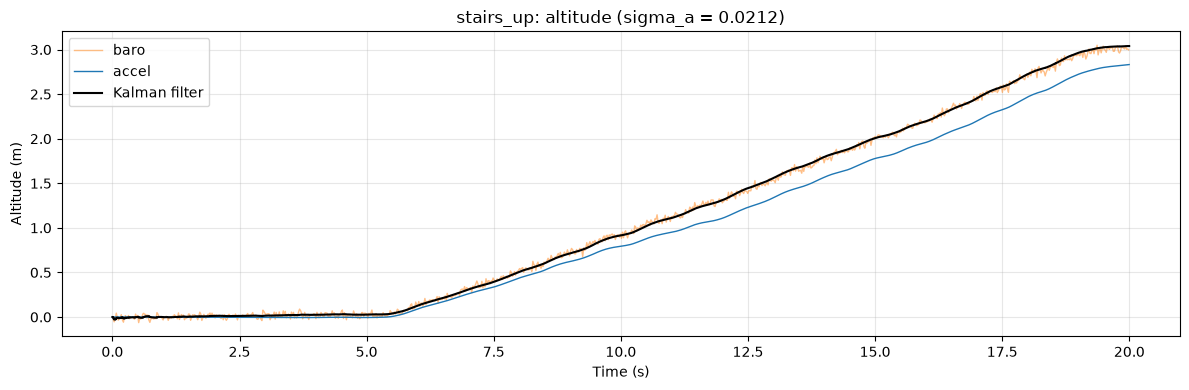

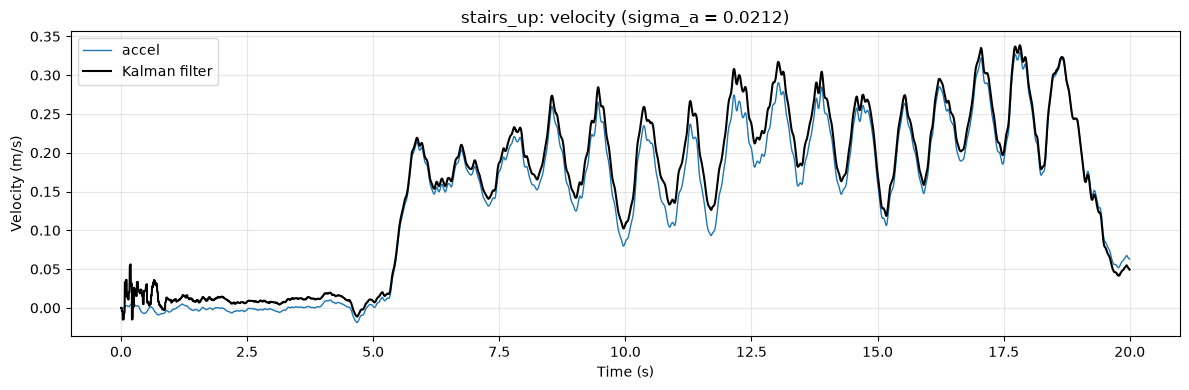

In [36]:
# Plot altitude
utils.plot_traces(
    [
        (rec["t_baro"], rec["baro_rel"], "baro", {"color": "tab:orange", "alpha": 0.5}),
        (rec["t_acc"], h_acc, "accel", {"color": "tab:blue"}),
        (t_kf, h_kf, "Kalman filter", {"color": "k", "lw": 1.5}),
    ],
    "Altitude (m)",
    title=f"{TUNE_NAME}: altitude (sigma_a = {SIGMA_A})",
)

# Plot velocity
utils.plot_traces(
    [
        (rec["t_acc"], v_acc, "accel", {"color": "tab:blue"}),
        (t_kf, v_kf, "Kalman filter", {"color": "k", "lw": 1.5}),
    ],
    "Velocity (m/s)",
    title=f"{TUNE_NAME}: velocity (sigma_a = {SIGMA_A})",
)

In [37]:
# Score: height change vs. truth, and velocity while standing still
print(f"True height change: {dh_true:.3f} m")
print(f"  baro:          {height_change(rec['t_baro'], rec['baro_rel'], REF_TIME_S):.3f} m")
print(f"  accel:         {height_change(rec['t_acc'], h_acc, REF_TIME_S):.3f} m")
print(f"  Kalman filter: {height_change(t_kf, h_kf, REF_TIME_S):.3f} m")
print()
print("Velocity RMS while still (should be 0):")
print(f"  accel:         {still_velocity_rms(rec['t_acc'], v_acc, REF_TIME_S):.3f} m/s")
print(f"  Kalman filter: {still_velocity_rms(t_kf, v_kf, REF_TIME_S):.3f} m/s")

True height change: 3.088 m
  baro:          2.905 m
  accel:         2.692 m
  Kalman filter: 2.928 m

Velocity RMS while still (should be 0):
  accel:         0.143 m/s
  Kalman filter: 0.144 m/s


## Tuning: Sweep sigma_a

The measured `SIGMA_A` only describes the accelerometer at rest. While walking, footsteps and small tilts add errors that the at-rest number doesn't include, so the filter may trust the accelerometer too much. Increasing `sigma_a` tells the filter to trust the accelerometer less and the barometer more:

* **Too small**: the estimate follows the accelerometer and lags behind or overshoots the barometer.
* **Too large**: the estimate follows the barometer, and the velocity gets noisy.

 sigma_a   height change   still v RMS
  0.0212         2.928 m       0.144 m/s
  0.1000         2.913 m       0.135 m/s
  0.5000         2.907 m       0.130 m/s
  1.0000         2.907 m       0.130 m/s
  5.0000         2.906 m       0.147 m/s


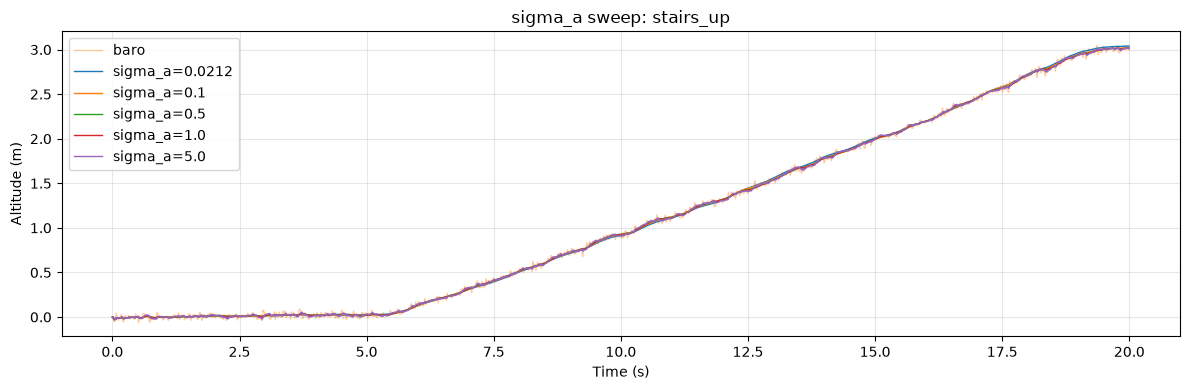

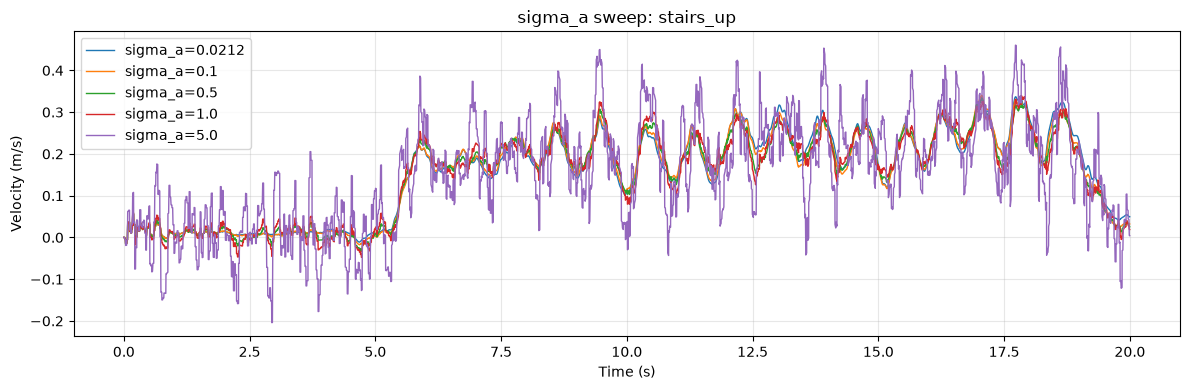

In [38]:
# Choose sigma_a values to try (m/s²)
sigma_as = [SIGMA_A, 0.1, 0.5, 1.0, 5.0]

# Run a filter for each value
h_traces = [(rec["t_baro"], rec["baro_rel"], "baro", {"color": "tab:orange", "alpha": 0.4})]
v_traces = []
print(f"{'sigma_a':>8}  {'height change':>14}  {'still v RMS':>12}")
for sa in sigma_as:
    t_kf, h_kf, v_kf = run_kalman_filter(rec, sa, SIGMA_B)
    h_traces.append((t_kf, h_kf, f"sigma_a={sa}"))
    v_traces.append((t_kf, v_kf, f"sigma_a={sa}"))
    dh = height_change(t_kf, h_kf, REF_TIME_S)
    v_rms = still_velocity_rms(t_kf, v_kf, REF_TIME_S)
    print(f"{sa:8.4f}  {dh:12.3f} m  {v_rms:10.3f} m/s")

# Plot altitude and velocity for each value
utils.plot_traces(h_traces, "Altitude (m)", title=f"sigma_a sweep: {TUNE_NAME}")
utils.plot_traces(v_traces, "Velocity (m/s)", title=f"sigma_a sweep: {TUNE_NAME}")

Pick the value that tracks the barometer's altitude without lag while keeping the velocity smooth.

In [39]:
# Tuned accelerometer noise (pick from the sweep above)
SIGMA_A_TUNED = 0.5

## Evaluation on Held-Out Recordings

Now run the tuned filter on the recordings we didn't use for tuning. If it does well here, we didn't just overfit to one stair climb.

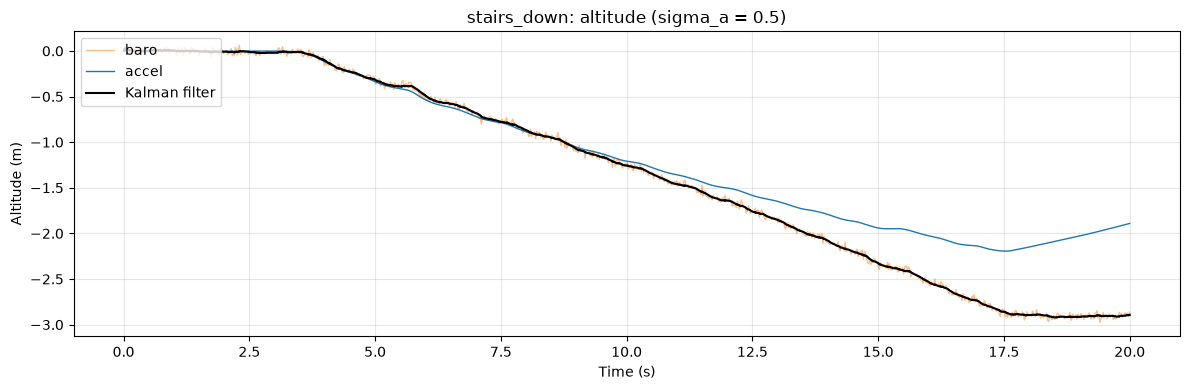

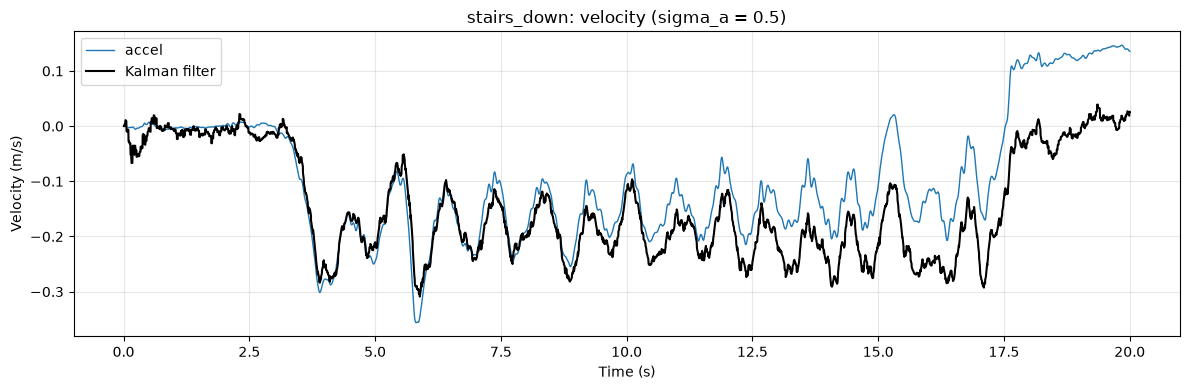

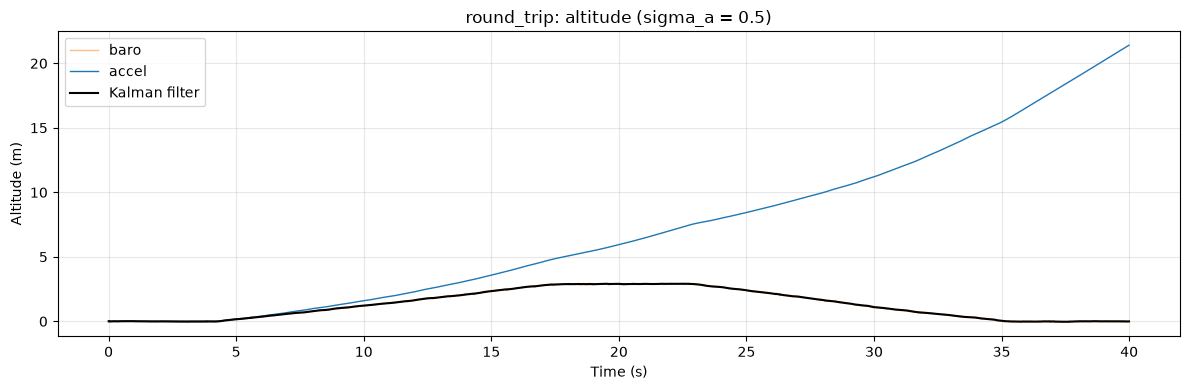

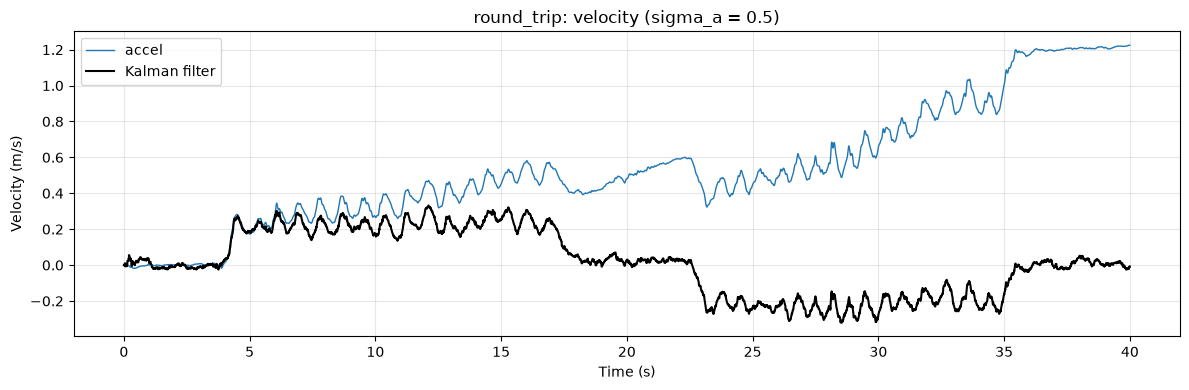

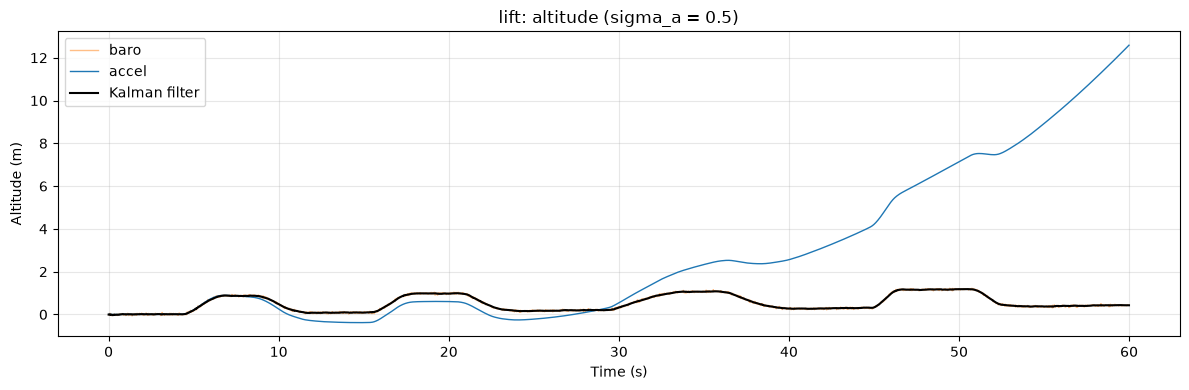

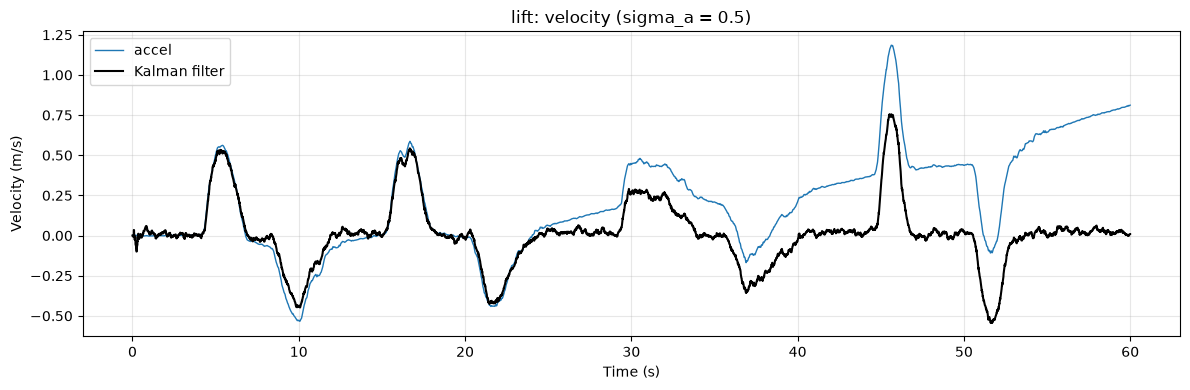

In [40]:
# Run the tuned filter on every other recording
results = []
for name, (path, dh_true) in RECORDINGS.items():
    if name == TUNE_NAME:
        continue
    rec = load_and_reference(path, REF_TIME_S)
    v_acc, h_acc = integrate_accel(rec["t_acc"], rec["az_rel"])
    t_kf, h_kf, v_kf = run_kalman_filter(rec, SIGMA_A_TUNED, SIGMA_B)

    # Plot altitude and velocity
    utils.plot_traces(
        [
            (rec["t_baro"], rec["baro_rel"], "baro", {"color": "tab:orange", "alpha": 0.5}),
            (rec["t_acc"], h_acc, "accel", {"color": "tab:blue"}),
            (t_kf, h_kf, "Kalman filter", {"color": "k", "lw": 1.5}),
        ],
        "Altitude (m)",
        title=f"{name}: altitude (sigma_a = {SIGMA_A_TUNED})",
    )
    utils.plot_traces(
        [
            (rec["t_acc"], v_acc, "accel", {"color": "tab:blue"}),
            (t_kf, v_kf, "Kalman filter", {"color": "k", "lw": 1.5}),
        ],
        "Velocity (m/s)",
        title=f"{name}: velocity (sigma_a = {SIGMA_A_TUNED})",
    )

    # Save the scores for the summary table
    results.append((
        name,
        dh_true,
        height_change(rec["t_baro"], rec["baro_rel"], REF_TIME_S),
        height_change(rec["t_acc"], h_acc, REF_TIME_S),
        height_change(t_kf, h_kf, REF_TIME_S),
        still_velocity_rms(rec["t_acc"], v_acc, REF_TIME_S),
        still_velocity_rms(t_kf, v_kf, REF_TIME_S),
    ))

In [41]:
# Summary table
print(f"{'':12}{'--------- height change (m) ---------':>40}   {'-- still v RMS (m/s) --':>24}")
print(f"{'recording':12}{'true':>8}{'baro':>10}{'accel':>10}{'KF':>10}   {'accel':>11}{'KF':>11}")
for name, dh_true, dh_b, dh_a, dh_k, v_a, v_k in results:
    true = f"{dh_true:8.3f}" if dh_true is not None else f"{'n/a':>8}"
    print(f"{name:12}{true}{dh_b:10.3f}{dh_a:10.3f}{dh_k:10.3f}   {v_a:11.3f}{v_k:11.3f}")

               --------- height change (m) ---------    -- still v RMS (m/s) --
recording       true      baro     accel        KF         accel         KF
stairs_down   -3.088    -2.905    -2.023    -2.906         0.092      0.022
round_trip     0.000    -0.001    20.198     0.000         0.856      0.022
lift             n/a     0.424    11.797     0.429         0.552      0.026


## Takeaways

* The Kalman filter follows the accelerometer in the short term (smooth and responsive) and the barometer in the long term (no drift).
* We get a smooth vertical velocity with no lag, even though neither sensor measures velocity well on its own. The barometer never measures velocity, but its corrections to the altitude also correct the velocity.
* The filter inherits the barometer's long-term errors. If the barometer reads the height change a few percent low (e.g. from temperature), so does the filter.
* `sigma_b` comes straight from the static recording, but `sigma_a` needs tuning: the at-rest noise doesn't include footsteps and tilt.